# Bean Leaf Disease Classifier
**Goal:** a farmer uploads a photo of a bean leaf and the model says whether it is healthy or has a disease.
## 1. Data reading and understanding
In this section we unzip the dataset and look at how it is organised.

In [12]:
import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

### 1.1 Getting the dataset

**Source:** [Bean Disease Dataset on Kaggle](https://www.kaggle.com/datasets/therealoise/bean-disease-dataset), real photos of bean leaves in 3 classes: `healthy`, `angular_leaf_spot` and `bean_rust`.

There are two ways to get it:
- **Option A (default):** download `archive.zip` from the link above and save it in `data/raw_data/`
- **Option B:** set `DOWNLOAD_FROM_KAGGLE = True` below and the notebook downloads it with `kagglehub` (needs `pip install kagglehub`)

In [3]:
import shutil   # add this to your imports cell if you prefer

PROJECT_ROOT = ".."
RAW_DIR = os.path.join(PROJECT_ROOT, "data", "raw_data")
ZIP_PATH = os.path.join(RAW_DIR, "archive.zip")

DOWNLOAD_FROM_KAGGLE = True    # True = download from Kaggle instead of using the zip file

In [8]:
if DOWNLOAD_FROM_KAGGLE:
    import kagglehub
    downloaded_path = kagglehub.dataset_download("therealoise/bean-disease-dataset")
    print("Downloaded to:", downloaded_path)
    shutil.copytree(downloaded_path, RAW_DIR, dirs_exist_ok=True)   # copy into our project
else:
    with zipfile.ZipFile(ZIP_PATH) as z:
        z.extractall(RAW_DIR)

for folder, sub_folders, files in os.walk(RAW_DIR):
    print(folder, "->", len(sub_folders), "folders,", len(files), "files")

Downloaded to: /home/jonathan/.cache/kagglehub/datasets/therealoise/bean-disease-dataset/versions/1
../data/raw_data -> 1 folders, 1 files
../data/raw_data/Bean_Dataset -> 3 folders, 0 files
../data/raw_data/Bean_Dataset/bean_rust -> 0 folders, 330 files
../data/raw_data/Bean_Dataset/angular_leaf_spot -> 0 folders, 330 files
../data/raw_data/Bean_Dataset/healthy -> 0 folders, 330 files


### 1.2 Classes and number of images

The folder name is the label of every image inside it. we are going to list the classes and count the images in each one.

In [4]:
DATASET_DIR = os.path.join(RAW_DIR, "Bean_Dataset")
class_names = sorted(os.listdir(DATASET_DIR))
print("Classes:", class_names)

counts = {}
for class_name in class_names:
    counts[class_name] = len(os.listdir(os.path.join(DATASET_DIR, class_name)))

counts_table = pd.DataFrame({"images": counts})
counts_table

Classes: ['angular_leaf_spot', 'bean_rust', 'healthy']


,images
angular_leaf_spot,330
bean_rust,330
healthy,330


### 1.3 What do the leaves look like?

Five random images from each class.

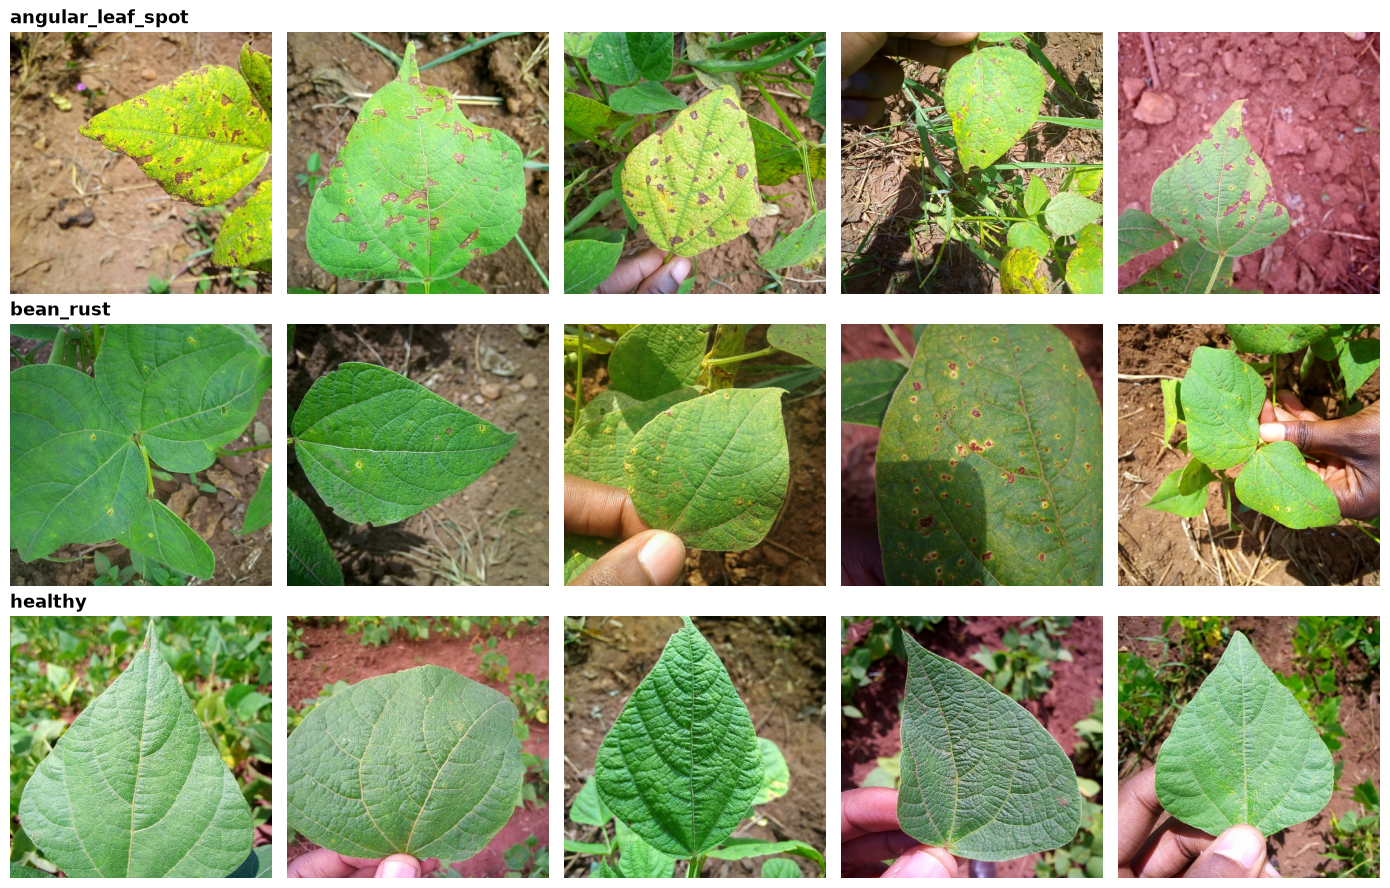

In [12]:
import random
random.seed(42)

fig, axes = plt.subplots(len(class_names), 5, figsize=(14, 9))

for row, class_name in enumerate(class_names):
    folder = os.path.join(DATASET_DIR, class_name)
    chosen = random.sample(os.listdir(folder), 5)
    for col, filename in enumerate(chosen):
        axes[row, col].imshow(Image.open(os.path.join(folder, filename)))
        axes[row, col].axis("off")
    axes[row, 0].set_title(class_name, loc="left", fontsize=13, fontweight="bold")

plt.tight_layout()
plt.show()

### 1.4 Image properties

The model needs images of one fixed size, so we check the size, colour mode and file format of every image.

In [6]:
rows = []
for class_name in class_names:
    folder = os.path.join(DATASET_DIR, class_name)
    for filename in os.listdir(folder):
        image = Image.open(os.path.join(folder, filename))
        rows.append({"class": class_name, "width": image.size[0], "height": image.size[1],
                     "mode": image.mode, "format": image.format})

image_info = pd.DataFrame(rows)

print("Different sizes found:")
print(image_info[["width", "height"]].drop_duplicates().to_string(index=False))
print("\nColour modes:\n", image_info["mode"].value_counts().to_string())
print("\nFile formats:\n", image_info["format"].value_counts().to_string())

Different sizes found:
 width  height
   500     500

Colour modes:
 mode
RGB    990

File formats:
 format
JPEG    990


### 1.5 What I observe

**each class has exactly 330 images** (990 in total), so the dataset is perfectly balanced. another thing is **all images are 500 x 500 pixels, RGB, JPEG**. No conversion is needed, we only have to resize them for the model later. also **Angular leaf spot:** brown, angular spots that are often surrounded by yellow patches, and some leaves are turning *yellow* while **Bean rust:** the signs are subtler, with many small pale or rusty dots on a mostly green leaf. I think this will probably be the hardest class for the model also **Healthy:** an even green leaf with clear veins and no spots.

**Photo conditions:** this images are real field photos, with soil, other plants and hands in the background. The diseased leaves are often photographed against bare soil, while healthy leaves more often fill the frame or sit among green plants. The model could learn these backgrounds instead of the disease, so we will use data augmentation to reduce that risk.

## 2. Data cleaning

Before training we check for two problems:
1. **Broken images** that cannot be opened.
2. **Duplicate images.** If the same photo ends up in both the training set and the test set, the model has already "seen the answer" and the test score looks better than it really is (this is called *data leakage*).

To find duplicates we compute a fingerprint (MD5 hash) of every file. Identical files always have the same fingerprint.
We do not delete anything from the raw folder. We only build a list of the good images to use.

In [ ]:
import hashlib

seen = {}                # fingerprint -the first file that had it
broken_files = []
duplicate_files = []     # pairs of (duplicate, original)

for class_name in class_names:
    folder = os.path.join(DATASET_DIR, class_name)
    for filename in sorted(os.listdir(folder)):
        path = os.path.join(folder, filename)

        # can the image be opened?
        try:
            Image.open(path).verify()
        except Exception:
            broken_files.append(path)
            continue

        # have we already seen a file with exactly the same content?
        with open(path, "rb") as f:
            fingerprint = hashlib.md5(f.read()).hexdigest()
        if fingerprint in seen:
            duplicate_files.append((path, seen[fingerprint]))
        else:
            seen[fingerprint] = path

print("Broken images:   ", len(broken_files))
print("Broken images:   ", len(broken_files))
print("Exact duplicates:", len(duplicate_files))
for duplicate, original in duplicate_files[:10]:
    print("  ", duplicate, "is the same as", original)

Broken images:    0
Exact duplicates: 0


In [14]:
bad_paths = set(broken_files) | {duplicate for duplicate, original in duplicate_files}

clean_images = {}        # class name -> list of good image paths
for class_name in class_names:
    folder = os.path.join(DATASET_DIR, class_name)
    paths = [os.path.join(folder, f) for f in sorted(os.listdir(folder))]
    clean_images[class_name] = [p for p in paths if p not in bad_paths]

pd.DataFrame({"before cleaning": counts,
              "after cleaning": {c: len(v) for c, v in clean_images.items()}})

,before cleaning,after cleaning
angular_leaf_spot,330,330
bean_rust,330,330
healthy,330,330


### Cleaning result
We found 0 broken images and 0 exact duplicates, so all 330 images in each class are kept (990 in total).

## 3. Splitting the data
**Train (70%)** for the model to learns from these images , **Validation (15%)** which will be used *during* training to tune the model and stop at the right time and **Test (15%)** used **once at the end** to measure how good the model really is on unseen images

We split **each class separately**, so train, validation and test all contain the same share of every class. We shuffle first so the split is random, and we fix the random seed so we get the same split every time.

In [15]:
import json
import random

TRAIN_SIZE = 0.70
VAL_SIZE = 0.15        # the test set gets everything that is left (about 15%)
SEED = 42

random.seed(SEED)
split_files = {"train": [], "val": [], "test": []}    # each item is (image path, class name)

for class_name in class_names:
    files = clean_images[class_name][:]               # copy of the list
    random.shuffle(files)

    n = len(files)
    n_train = int(n * TRAIN_SIZE)
    n_val = int(n * VAL_SIZE)

    split_files["train"] += [(p, class_name) for p in files[:n_train]]
    split_files["val"] += [(p, class_name) for p in files[n_train:n_train + n_val]]
    split_files["test"] += [(p, class_name) for p in files[n_train + n_val:]]

for split, items in split_files.items():
    print(split, ":", len(items), "images")

train : 690 images
val : 147 images
test : 153 images


**Safety check:** no image may appear in more than one split, otherwise we would have data leakage.

In [16]:
paths = {split: {path for path, class_name in items} for split, items in split_files.items()}

print("train & val overlap :", len(paths["train"] & paths["val"]))
print("train & test overlap:", len(paths["train"] & paths["test"]))
print("val & test overlap  :", len(paths["val"] & paths["test"]))

train & val overlap : 0
train & test overlap: 0
val & test overlap  : 0


### Copy the images into data/train, data/val and data/test

Each split gets one sub-folder per class, which is the layout the model will read from. We also save the class names so the model and the API always use the same label order. The raw data is not touched.

In [18]:
DATA_DIR = os.path.join(PROJECT_ROOT, "data")

# start fresh each time we run this cell (we only delete train / val / test)
for split in ["train", "val", "test"]:
    shutil.rmtree(os.path.join(DATA_DIR, split), ignore_errors=True)

for split, items in split_files.items():
    for path, class_name in items:
        destination = os.path.join(DATA_DIR, split, class_name)
        os.makedirs(destination, exist_ok=True)
        shutil.copy(path, destination)

with open(os.path.join(DATA_DIR, "class_names.json"), "w") as f:
    json.dump(class_names, f)

# check what we created
rows = []
for class_name in class_names:
    row = {"class": class_name}
    for split in ["train", "val", "test"]:
        row[split] = len(os.listdir(os.path.join(DATA_DIR, split, class_name)))
    rows.append(row)

split_table = pd.DataFrame(rows).set_index("class")
split_table["total"] = split_table.sum(axis=1)
split_table.loc["TOTAL"] = split_table.sum()
split_table

,train,val,test,total
class,,,,
angular_leaf_spot,230,49,51,330
bean_rust,230,49,51,330
healthy,230,49,51,330
TOTAL,690,147,153,990


## 4. Data visualizations
the features we are going to measure are **Class balance** across the train / validation / test sets, **Colour** (average red, green and blue value of each image) and **Brightness** of the images

### 4.1 Class balance across the splits

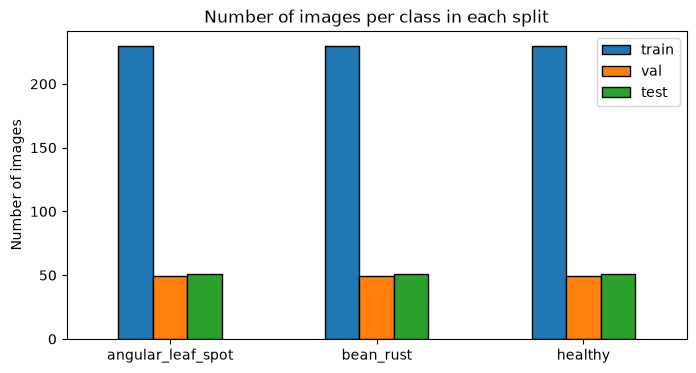

In [19]:
split_table.drop("TOTAL")[["train", "val", "test"]].plot(kind="bar", figsize=(8, 4), edgecolor="black")
plt.title("Number of images per class in each split")
plt.ylabel("Number of images")
plt.xlabel("")
plt.xticks(rotation=0)
plt.show()

**Interpretation**:\
The classes are **perfectly balanced**: every class has 230 training, 49 validation and 51 test images. The three splits have different sizes on purpose (70% / 15% / 15%), and the small difference between 49 and 51 comes only from rounding, the same for every class. Because no class is bigger than the others, the model cannot get a good score just by favouring one class, so **accuracy is a fair metric** here. We will still report precision, recall and F1 for each class, to see which disease the model finds hardest. The test set is small (51 images per class), so one wrong image changes a class score by about 2 percentage points. We should not read too much into small differences.

### 4.2 Colour and brightness of the images

Diseased leaves have spots and yellowing, so we expect their colours to differ from healthy leaves. For every image we compute the average **red**, **green** and **blue** value (0 to 255) and the average **brightness**. We shrink each image to 64 x 64 first, only to make this faster.

In [20]:
stats = []

for split, items in split_files.items():
    for path, class_name in items:
        image = Image.open(path).convert("RGB")
        small = np.array(image.resize((64, 64)))        # a 64 x 64 x 3 table of numbers

        stats.append({
            "class": class_name,
            "split": split,
            "red": small[:, :, 0].mean(),
            "green": small[:, :, 1].mean(),
            "blue": small[:, :, 2].mean(),
            "brightness": small.mean(),
        })

stats = pd.DataFrame(stats)
stats.groupby("class")[["red", "green", "blue", "brightness"]].mean().round(1)

,red,green,blue,brightness
class,,,,
angular_leaf_spot,129.2,134.9,73.9,112.7
bean_rust,119.8,119.6,77.1,105.5
healthy,122.3,142.8,87.5,117.5


#### Average colour per class

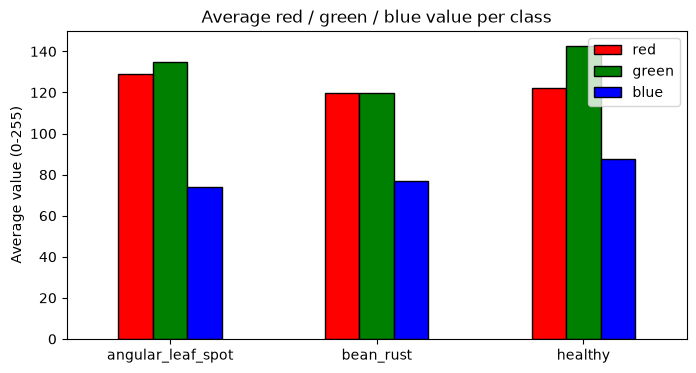

In [21]:
colour_means = stats.groupby("class")[["red", "green", "blue"]].mean()

colour_means.plot(kind="bar", figsize=(8, 4), color=["red", "green", "blue"], edgecolor="black")
plt.title("Average red / green / blue value per class")
plt.ylabel("Average value (0-255)")
plt.xlabel("")
plt.xticks(rotation=0)
plt.show()

**Interpretation**

**Healthy** leaves have the highest green (142.8) and the highest blue (87.5), and their green is clearly higher than their red (122.3). They look like an even, fresh green leaf. **Bean rust** has the lowest green (119.6): red and green are almost equal (119.8 vs 119.6), which gives a duller, yellow-brown tone. This matches the small rusty dots on the leaves. **Angular leaf spot** has the highest red (129.2) and the lowest blue (73.9). Brown spots and yellowing leaves are made of red and green with little blue, which fits what we saw in the photos.

The differences are only about 5 to 20 points out of 255, so **colour helps but cannot separate the classes alone**. The model also has to learn texture and shape (spots, veins).

Caution: the averages include the background. Red soil in the photos could raise the red value, so part of this difference may come from the background and not from the leaf.

#### Brightness per class

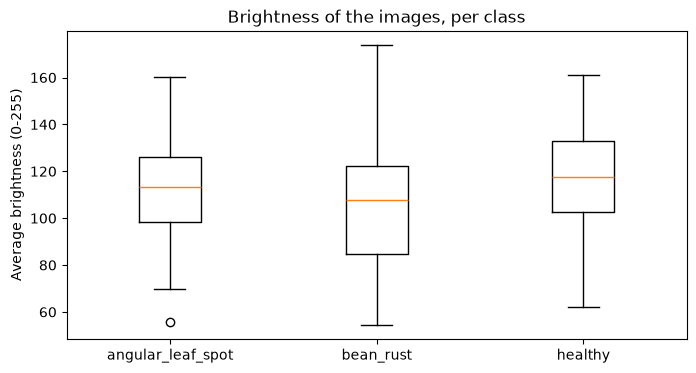

In [22]:
data = [stats[stats["class"] == c]["brightness"] for c in class_names]

plt.figure(figsize=(8, 4))
plt.boxplot(data)
plt.xticks(range(1, len(class_names) + 1), class_names)
plt.title("Brightness of the images, per class")
plt.ylabel("Average brightness (0-255)")
plt.show()

**Interpretation:**

The boxes overlap a lot. The median brightness is similar for all three classes (about 113 for angular leaf spot, 107 for bean rust and 118 for healthy), so **brightness alone cannot tell the classes apart**. That is good news, because the model cannot cheat by learning which class has brighter photos. Another thing inside every class the brightness varies a lot (from about 55 to 175), because some photos were taken in strong sun and others in shade. Bean rust varies the most.

A farmer's phone photos will have the same problem (sun, shade, cloudy days). So we will use **data augmentation** (random brightness and contrast changes, flips, rotations) when training, so the model learns to recognise the disease in any light.

## 5. Preparing the images for the model

The model needs:
1. every image resized to the **same size** (224 x 224)
2. images delivered in **batches** (32 at a time)
3. **data augmentation** during training (random flips, rotations, zoom, contrast)

We write this code into the files in `src/`, so that the notebook, the retraining code, the API and the UI all use **exactly the same preprocessing**. In the notebook we use `%%writefile` to save a cell as a `.py` file.

In [15]:
import sys
import tensorflow as tf

In [7]:
%load_ext autoreload
%autoreload 2

sys.path.append("..")       # now Python can find the src/ folder

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [8]:
%%writefile ../src/__init__.py
# makes src a Python package

Writing ../src/__init__.py


### 5.1 `src/config.py`: settings in one place
Paths and sizes are defined once here. The paths are built from the location of the file itself, so they work whether the code is started from the notebook, the API or Docker.

In [9]:
%%writefile ../src/config.py
"""Settings shared by the notebook, the retraining code, the API and the UI."""
import json
from pathlib import Path

# Project root = the folder that contains src/
BASE_DIR = Path(__file__).resolve().parent.parent

DATA_DIR = BASE_DIR / "data"
UPLOADS_DIR = DATA_DIR / "uploads"
MODELS_DIR = BASE_DIR / "models"
MODEL_PATH = MODELS_DIR / "bean_model.h5"

IMG_SIZE = (224, 224)     # every image is resized to 224 x 224
BATCH_SIZE = 32           # the model looks at 32 images at a time


def load_class_names():
    """The class order saved in data/class_names.json by the notebook."""
    with open(DATA_DIR / "class_names.json") as f:
        return json.load(f)

Writing ../src/config.py


### 5.2 `src/preprocessing.py`: the preprocessing functions

**Function and What they do:**
1. `list_images` : lists the image paths and labels in a folder like `data/train` 
2. `make_dataset` : reads, decodes and resizes the images and groups them into batches 
3. `build_augmentation` : random flip, rotation, zoom and contrast (only used while training) 
4. `validate_image` : checks that an uploaded file is a real image (used by the API) 
5. `image_to_array` : prepares ONE uploaded image for prediction, resized exactly like in training 

In [34]:
%%writefile ../src/preprocessing.py
"""Preprocessing: turning image files into data the model can use."""
import io
import os

import numpy as np
import tensorflow as tf
from PIL import Image
from tensorflow import keras
from tensorflow.keras import layers

from src.config import BATCH_SIZE, IMG_SIZE

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png")


def list_images(folder, class_names):
    """Return two lists: image paths and their label numbers (0, 1, 2).
    Expects the layout:  folder/<class_name>/<image files>"""
    paths, labels = [], []
    for label, class_name in enumerate(class_names):
        class_folder = os.path.join(folder, class_name)
        if not os.path.isdir(class_folder):
            continue
        for filename in sorted(os.listdir(class_folder)):
            if filename.lower().endswith(IMAGE_EXTENSIONS):
                paths.append(os.path.join(class_folder, filename))
                labels.append(label)
    return paths, labels


def load_and_resize(path, label):
    """Read one image file, decode it and resize it to 224 x 224 (values stay 0-255)."""
    image = tf.io.read_file(path)
    image = tf.io.decode_image(image, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    return image, label


def make_dataset(paths, labels, shuffle=False):
    """Turn lists of paths and labels into batches the model can read."""
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        dataset = dataset.shuffle(len(paths), seed=42)
    dataset = dataset.map(load_and_resize, num_parallel_calls=tf.data.AUTOTUNE)
    return dataset.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)


def build_augmentation():
    """Random changes applied to training images. Only active during training."""
        return keras.Sequential([
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(0.05),
        layers.RandomZoom(0.1),
        layers.RandomBrightness(0.15, value_range=(0, 255)),
        layers.RandomContrast(0.2),
    ], name="augmentation")


def validate_image(file_bytes):
    """Check that uploaded bytes are a real image. Returns a PIL image or raises ValueError."""
    try:
        Image.open(io.BytesIO(file_bytes)).verify()
        return Image.open(io.BytesIO(file_bytes)).convert("RGB")
    except Exception:
        raise ValueError("The file is not a valid image (use .jpg or .png).")


def image_to_array(pil_image):
    """PIL image -> array of shape (1, 224, 224, 3), resized the same way as in training."""
    array = np.asarray(pil_image, dtype=np.float32)
    array = tf.image.resize(array, IMG_SIZE).numpy()
    return np.expand_dims(array, axis=0)

Overwriting ../src/preprocessing.py


### 5.3 Using our own functions in the notebook
We import the functions we just saved and load the three splits as batches. The validation and test sets are not shuffled, so the predictions stay in the same order as the labels.

In [36]:
from src import config
from src.preprocessing import list_images, make_dataset, build_augmentation

class_names = config.load_class_names()
print("Classes:", class_names)

train_paths, train_labels = list_images(config.DATA_DIR / "train", class_names)
val_paths, val_labels = list_images(config.DATA_DIR / "val", class_names)
test_paths, test_labels = list_images(config.DATA_DIR / "test", class_names)
print("Images:", len(train_paths), "train,", len(val_paths), "val,", len(test_paths), "test")

train_ds = make_dataset(train_paths, train_labels, shuffle=True)
val_ds = make_dataset(val_paths, val_labels)
test_ds = make_dataset(test_paths, test_labels)

# look at one batch
for images, labels in train_ds.take(1):
    print("Batch of images:", images.shape)
    print("Batch of labels:", labels.shape)
    print("Pixel values from", images.numpy().min(), "to", images.numpy().max())

Classes: ['angular_leaf_spot', 'bean_rust', 'healthy']
Images: 690 train, 147 val, 153 test
Batch of images: (32, 224, 224, 3)
Batch of labels: (32,)
Pixel values from 0.0 to 255.0


### 5.4 Data augmentation
During training the model sees a slightly different version of each photo every epoch: flipped, rotated, zoomed, with changed contrast. It cannot just memorise the training photos, and it learns to recognise the disease in different lighting and angles, like the real photos a farmer will take. Augmentation is never used when predicting.

Here is one leaf, augmented 8 different ways:

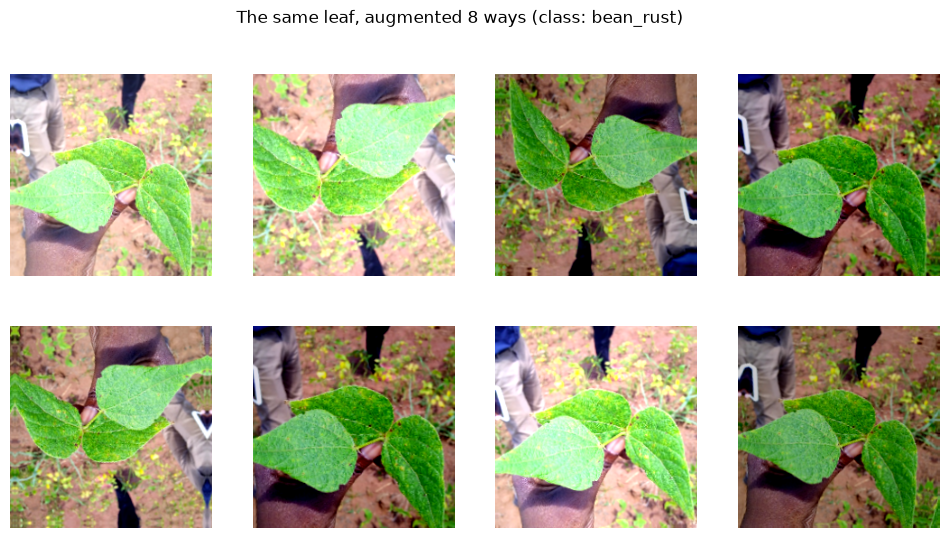

In [38]:
augmentation = build_augmentation()

for images, labels in train_ds.take(1):
    plt.figure(figsize=(12, 6))
    for i in range(8):
        augmented = augmentation(images[:1], training=True)[0].numpy()
        plt.subplot(2, 4, i + 1)
        plt.imshow(np.clip(augmented, 0, 255).astype("uint8"))
        plt.axis("off")
    plt.suptitle("The same leaf, augmented 8 ways (class: " + class_names[int(labels[0])] + ")")
    plt.show()

## 6. Modelling

We build two models and compare them:
1. a **baseline CNN** trained from scratch: simple, with no tricks
2. the **main model**: transfer learning with MobileNetV2, plus optimization techniques

### 6.1 `src/model.py`: evaluation functions
We save the evaluation code into `src/model.py` now, so the retraining code can reuse it later.

- **Accuracy:** the share of images predicted correctly
- **Loss:** how wrong the predicted probabilities are (lower is better)
- **Precision:** when the model says "rust", how often is it really rust?
- **Recall:** of all the real rust leaves, how many did the model find?
- **F1:** one number combining precision and recall

With 3 classes we use the **macro average**: compute each score per class, then average them, so every class counts equally.

In [29]:
%%writefile ../src/model.py
"""Model: evaluation functions (more functions are added in the next step)."""
import numpy as np


def predict_all(model, dataset):
    """Predict every image in a dataset. Returns the true labels and the predicted labels."""
    y_true = np.concatenate([labels.numpy() for images, labels in dataset])
    y_pred = np.argmax(model.predict(dataset, verbose=0), axis=1)
    return y_true, y_pred


def evaluate_model(model, dataset, class_names):
    """Loss, accuracy, macro precision / recall / F1, per-class F1 and the confusion matrix."""
    loss, accuracy = model.evaluate(dataset, verbose=0)
    y_true, y_pred = predict_all(model, dataset)

    n = len(class_names)
    matrix = np.zeros((n, n), dtype=int)       # rows = true class, columns = predicted class
    for true, predicted in zip(y_true, y_pred):
        matrix[true, predicted] += 1

    true_positives = np.diag(matrix)
    predicted_totals = matrix.sum(axis=0)
    actual_totals = matrix.sum(axis=1)
    precision = np.divide(true_positives, predicted_totals, out=np.zeros(n), where=predicted_totals > 0)
    recall = np.divide(true_positives, actual_totals, out=np.zeros(n), where=actual_totals > 0)
    both = precision + recall
    f1 = np.divide(2 * precision * recall, both, out=np.zeros(n), where=both > 0)

    return {
        "loss": round(float(loss), 4),
        "accuracy": round(float(accuracy), 4),
        "precision": round(float(precision.mean()), 4),
        "recall": round(float(recall.mean()), 4),
        "f1": round(float(f1.mean()), 4),
        "per_class_f1": {name: round(float(v), 4) for name, v in zip(class_names, f1)},
        "confusion_matrix": matrix.tolist(),
        "images": int(len(y_true)),
    }

Writing ../src/model.py


### 6.2 Baseline CNN
Three blocks of convolution + pooling to find patterns, then a small dense layer that decides the class. No pre-training, no augmentation, no regularization, so this is a plain "vanilla" model.

In [30]:
from tensorflow import keras
from tensorflow.keras import layers
from src.model import evaluate_model

keras.utils.set_random_seed(42)       # makes the results repeatable

baseline = keras.Sequential([
    layers.Input(shape=config.IMG_SIZE + (3,)),
    layers.Rescaling(1 / 255),                              # pixel values 0-255 -> 0-1
    layers.Conv2D(16, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(32, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Conv2D(64, 3, activation="relu"), layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(len(class_names), activation="softmax"),   # one probability per class
], name="baseline_cnn")

baseline.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
baseline.summary()

Model: "baseline_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 43264)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     2,768,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,792,739 (10.65 MB)

 Trainable params: 2,792,739 (10.65 MB)

 Non-trainable params: 0 (0.00 B)

In [31]:
baseline_run = baseline.fit(train_ds, validation_data=val_ds, epochs=10)

Epoch 1/10


/home/jonathan/miniconda3/envs/beanguard/lib/python3.12/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(
W0000 00:00:1795354801.238189   25337 cpu_allocator_impl.cc:82] Allocation of 100933632 exceeds 10% of free system memory.
W0000 00:00:1795354801.645458   25337 cpu_allocator_impl.cc:82] Allocation of 48664576 exceeds 10% of free system memory.
W0000 00:00:1795354802.217837   25335 cpu_allocator_impl.cc:82] Allocation of 48664576 exceeds 10% of free system memory.
W0000 00:00:1795354802.685797   25334 cpu_allocator_impl.cc:82] Allocation of 50466816 exceeds 10% of free system memory.
W0000 00:00:1795354802.685868   25334 cpu_allocator_impl.cc:82] Allocation of 100933632 exceeds 10% of free system memory.


22/22 ━━━━━━━━━━━━━━━━━━━━ 38s 2s/step - accuracy: 0.4609 - loss: 1.1305 - val_accuracy: 0.4626 - val_loss: 1.0068
Epoch 2/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 39s 2s/step - accuracy: 0.6116 - loss: 0.8379 - val_accuracy: 0.5918 - val_loss: 0.9156
Epoch 3/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 36s 2s/step - accuracy: 0.6841 - loss: 0.7179 - val_accuracy: 0.7143 - val_loss: 0.7096
Epoch 4/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 35s 1s/step - accuracy: 0.7681 - loss: 0.5606 - val_accuracy: 0.6667 - val_loss: 0.8646
Epoch 5/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 30s 1s/step - accuracy: 0.8101 - loss: 0.4603 - val_accuracy: 0.7347 - val_loss: 0.6620
Epoch 6/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 29s 1s/step - accuracy: 0.8623 - loss: 0.3693 - val_accuracy: 0.6871 - val_loss: 0.7998
Epoch 7/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 32s 1s/step - accuracy: 0.8812 - loss: 0.2876 - val_accuracy: 0.6803 - val_loss: 0.9542
Epoch 8/10
22/22 ━━━━━━━━━━━━━━━━━━━━ 37s 1s/step - accuracy: 0.9261 - loss: 0.2132 - val_accuracy: 0.7143 - val_loss: 1.1413
Epo

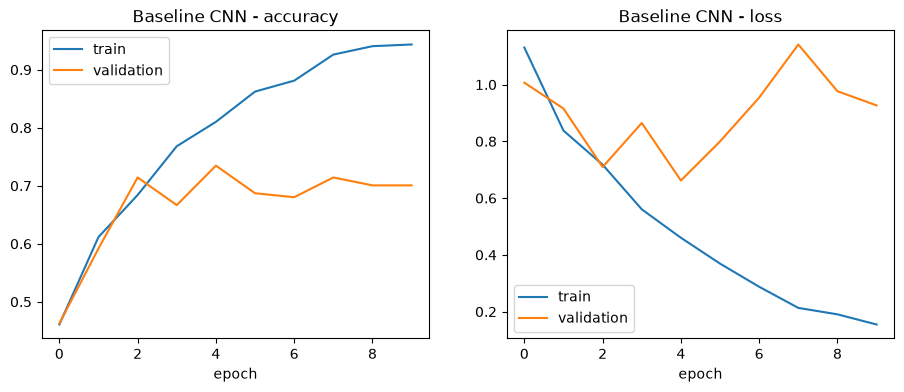

In [32]:
def plot_history(history, title):
    plt.figure(figsize=(11, 4))

    plt.subplot(1, 2, 1)
    plt.plot(history["accuracy"], label="train")
    plt.plot(history["val_accuracy"], label="validation")
    plt.title(title + " - accuracy")
    plt.xlabel("epoch")
    plt.legend()

    plt.subplot(1, 2, 2)
    plt.plot(history["loss"], label="train")
    plt.plot(history["val_loss"], label="validation")
    plt.title(title + " - loss")
    plt.xlabel("epoch")
    plt.legend()
    plt.show()


plot_history(baseline_run.history, "Baseline CNN")

In [33]:
baseline_val = evaluate_model(baseline, val_ds, class_names)

print("Baseline CNN on the VALIDATION set:")
for name in ["loss", "accuracy", "precision", "recall", "f1"]:
    print(f"  {name:10s}: {baseline_val[name]}")

Baseline CNN on the VALIDATION set:
  loss      : 0.9267
  accuracy  : 0.7007
  precision : 0.7023
  recall    : 0.7007
  f1        : 0.6994


**Interpretation:**
- **The baseline learns, but it over-fits.** Training accuracy keeps rising from 46% to 94%, while validation accuracy stays between 70% and 73% after epoch 5. The validation loss is lowest at epoch 5 (0.66), then rises to 1.14 at epoch 8 while the training loss keeps falling to 0.15. From epoch 5 the model starts memorising the training photos instead of learning patterns that work on new ones. The final gap between training and validation accuracy is about 24 points.
- **70% is far above chance** (33% for 3 balanced classes), so the model has learned real differences. But it still misclassifies about 3 out of 10 validation leaves, which a farmer could not rely on.
- **Precision (0.702), recall (0.701) and F1 (0.699) are almost identical to the accuracy.** With balanced classes there is no class that is systematically favoured. (Macro recall equals accuracy exactly here, because every class has the same number of validation images.)
- The validation accuracy jumps up and down from epoch to epoch (e.g. 73% to 69% to 68%). With only 147 validation images, one image is 0.7% of the score, so small changes are partly noise.
- **What we expect the main model to improve:** transfer learning from MobileNetV2 (pre-trained on ImageNet) gives it a head start on recognising textures and shapes. Data augmentation, dropout and early stopping reduce the over-fitting, and early stopping would have stopped this baseline at epoch 5, where the validation loss was lowest.

In [39]:
print("Per-class F1:", baseline_val["per_class_f1"])
print("\nConfusion matrix (rows = true class, columns = predicted class):")
print(pd.DataFrame(baseline_val["confusion_matrix"], index=class_names, columns=class_names))

Per-class F1: {'angular_leaf_spot': 0.6731, 'bean_rust': 0.6374, 'healthy': 0.7879}

Confusion matrix (rows = true class, columns = predicted class):
                   angular_leaf_spot  bean_rust  healthy
angular_leaf_spot                 35          8        6
bean_rust                         15         29        5
healthy                            5          5       39
